# SberAutoSubscription. Part 2: model

Predict from the visit data (source, device, city) if the user will do a target action. The metric is ROC-AUC, the guide asks for about 0.65. Final training is in `pipeline.py`, the service is in `main.py`.

In [1]:
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import chi2_contingency

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OrdinalEncoder, OneHotEncoder, StandardScaler, FunctionTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import roc_auc_score, roc_curve, f1_score, precision_score, recall_score, confusion_matrix

import warnings
warnings.filterwarnings('ignore')

# smaller pictures, otherwise the notebook gets too heavy
plt.rcParams['figure.dpi'] = 72

In [2]:
sessions = pd.read_csv('data/ga_sessions.csv', dtype=str)
target = pd.read_csv('data/target.csv', dtype={'session_id': str})

df = sessions.merge(target[['session_id', 'target']], on='session_id')
print(df.shape)
print(round(df['target'].mean(), 4))

(1732266, 19)
0.029


hits_count from target.csv is not used, it's known only after the visit ends, so it would be a leak.

## Features

Same cleaning as in the EDA but inside a function, because the service will get raw rows. New features: hour, day of week, screen width and height, and flags for organic traffic, social media ads and Moscow/SPb.

In [3]:
# social media sources from the guide
SOCIAL = ['QxAxdyPLuQMEcrdZWdWb', 'MvfHsxITijuriZxsqZqt', 'ISrKoXQCxqqYvAZICvjs',
          'IZEXUFLARCUMynmHNBGo', 'PlbkrSYoHuZBWfYjYnfw', 'gVRrcxiDQubJiljoTbGm']

CAT_FEATURES = ['utm_source', 'utm_medium', 'utm_campaign', 'utm_adcontent', 'utm_keyword',
                'device_category', 'device_os', 'device_brand', 'device_browser', 'geo_country', 'geo_city']
NUM_FEATURES = ['visit_number', 'visit_hour', 'visit_weekday', 'screen_width', 'screen_height',
                'is_organic', 'is_social', 'is_moscow_spb']


def prepare(df):
    df = df.copy()
    df = df.replace('(not set)', np.nan)

    # device_os from the brand, like in the EDA
    df.loc[df['device_os'].isna() & (df['device_brand'] == 'Apple'), 'device_os'] = 'iOS'
    df.loc[df['device_os'].isna() & df['device_brand'].notna() & (df['device_brand'] != 'Apple')
           & df['device_category'].isin(['mobile', 'tablet']), 'device_os'] = 'Android'
    df[CAT_FEATURES] = df[CAT_FEATURES].fillna('other')

    df['visit_number'] = pd.to_numeric(df['visit_number'])
    df['visit_hour'] = pd.to_datetime(df['visit_time'], format='%H:%M:%S').dt.hour
    df['visit_weekday'] = pd.to_datetime(df['visit_date']).dt.day_of_week

    # '360x720' -> width and height, an empty resolution becomes '0x0' and is treated as wrong below
    res = df['device_screen_resolution'].fillna('0x0').str.split('x')
    df['screen_width'] = pd.to_numeric(res.str[0], errors='coerce')
    df['screen_height'] = pd.to_numeric(res.str[1], errors='coerce')
    bad = ((df['screen_width'] < 100) | (df['screen_height'] < 100)
           | (df['screen_width'] > 8000) | (df['screen_height'] > 8000))
    df.loc[bad, ['screen_width', 'screen_height']] = np.nan

    df['is_organic'] = df['utm_medium'].isin(['organic', 'referral', '(none)']).astype(int)
    df['is_social'] = df['utm_source'].isin(SOCIAL).astype(int)
    df['is_moscow_spb'] = df['geo_city'].isin(['Moscow', 'Saint Petersburg']).astype(int)
    return df[CAT_FEATURES + NUM_FEATURES]


X = prepare(df)
y = df['target'].values
X.head()

,utm_source,utm_medium,utm_campaign,utm_adcontent,utm_keyword,device_category,device_os,device_brand,device_browser,geo_country,geo_city,visit_number,visit_hour,visit_weekday,screen_width,screen_height,is_organic,is_social,is_moscow_spb
0,ZpYIoDJMcFzVoPFsHGJL,banner,LEoPHuyFvzoNfnzGgfcd,vCIpmpaGBnIQhyYNkXqp,puhZPIYqKXeFPaUviSjo,mobile,Android,Huawei,Chrome,Russia,Zlatoust,1,14,2,360.0,720.0,0,0,0
1,MvfHsxITijuriZxsqZqt,cpm,FTjNLDyTrXaWYgZymFkV,xhoenQgDQsgfEPYNPwKO,IGUCNvHlhfHpROGclCit,mobile,Android,Samsung,Samsung Internet,Russia,Moscow,1,8,6,385.0,854.0,0,1,1
2,ZpYIoDJMcFzVoPFsHGJL,banner,LEoPHuyFvzoNfnzGgfcd,vCIpmpaGBnIQhyYNkXqp,puhZPIYqKXeFPaUviSjo,mobile,Android,Huawei,Chrome,Russia,Krasnoyarsk,1,2,1,360.0,720.0,0,0,0
3,kjsLglQLzykiRbcDiGcD,cpc,other,NOBKLgtuvqYWkXQHeYWM,other,mobile,Android,Xiaomi,Chrome,Russia,Moscow,1,5,5,393.0,786.0,0,0,1
4,kjsLglQLzykiRbcDiGcD,cpc,other,other,other,mobile,Android,Xiaomi,Chrome,Russia,Moscow,2,5,5,393.0,786.0,0,0,1


In [4]:
X[CAT_FEATURES].nunique().sort_values()

device_category       3
device_os            13
utm_medium           55
device_browser       55
geo_country         159
device_brand        200
utm_source          281
utm_adcontent       281
utm_campaign        407
utm_keyword        1193
geo_city           2389
dtype: int64

In [5]:
for col in ['utm_keyword', 'geo_city', 'utm_campaign', 'device_brand']:
    counts = X[col].value_counts()
    frequent = counts[counts >= 100]
    print(col, len(counts), 'values,', len(frequent), 'of them 100+ times, cover', round(frequent.sum() / len(X) * 100, 1), '%')

utm_keyword 1193 values, 209 of them 100+ times, cover 99.2 %
geo_city 2389 values, 330 of them 100+ times, cover 98.9 %
utm_campaign 407 values, 188 of them 100+ times, cover 99.7 %
device_brand 200 values, 47 of them 100+ times, cover 99.9 %


A lot of rare values: 330 of 2389 cities cover 98.9% of visits. So in the encoder everything with fewer than 100 visits goes into one group.

## Dependence between features

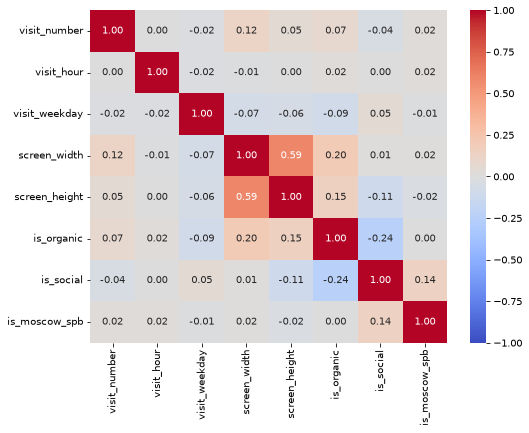

In [6]:
plt.figure(figsize=(8, 6))
sns.heatmap(X[NUM_FEATURES].corr(), annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1)
plt.show()

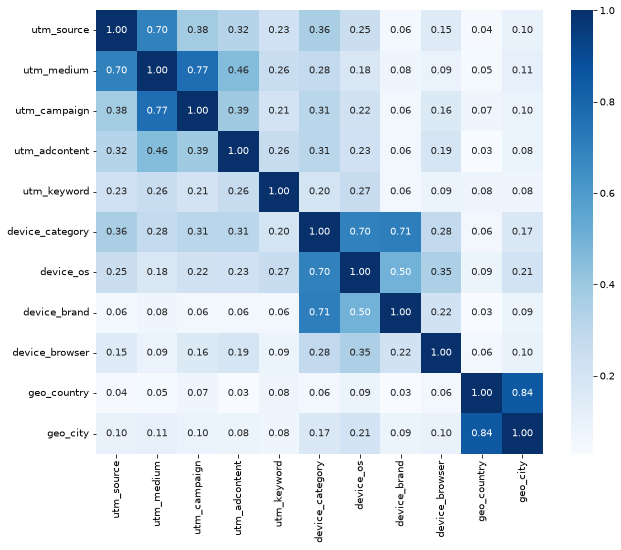

In [7]:
# for categorical features Cramer's V instead of correlation
def cramers_v(a, b):
    table = pd.crosstab(a, b)
    chi2 = chi2_contingency(table)[0]
    n = table.values.sum()
    return np.sqrt(chi2 / n / (min(table.shape) - 1))


sample = X.sample(300_000, random_state=42)
cramers = pd.DataFrame(index=CAT_FEATURES, columns=CAT_FEATURES, dtype=float)
for a in CAT_FEATURES:
    for b in CAT_FEATURES:
        if a == b:
            cramers.loc[a, b] = 1
        else:
            cramers.loc[a, b] = cramers_v(sample[a], sample[b])

plt.figure(figsize=(10, 8))
sns.heatmap(cramers, annot=True, fmt='.2f', cmap='Blues')
plt.show()

Numeric features almost don't correlate, only screen width and height (0.59). The is_* flags are made from utm_medium, utm_source and geo_city, so they repeat them. Strong pairs in the categorical ones: utm_medium with utm_campaign and utm_source (0.77 and 0.70), country with city (0.84), device_category with brand and os (around 0.7). For logistic regression this is bad, for boosting less so, the extra features I check later with importance.

## Split

By client, so one person is not in train and test at the same time. 60% train, 20% valid for choosing parameters, 20% test.

In [8]:
clients = df['client_id'].unique()
train_clients, other_clients = train_test_split(clients, test_size=0.4, random_state=42)
valid_clients, test_clients = train_test_split(other_clients, test_size=0.5, random_state=42)

train = df['client_id'].isin(train_clients).values
valid = df['client_id'].isin(valid_clients).values
test = df['client_id'].isin(test_clients).values

X_train, y_train = X[train], y[train]
X_valid, y_valid = X[valid], y[valid]
X_test, y_test = X[test], y[test]
print(len(y_train), len(y_valid), len(y_test))
print(round(y_train.mean(), 4), round(y_valid.mean(), 4), round(y_test.mean(), 4))

1038283 346420 347563
0.0289 0.0295 0.029


## Baseline

Conversion of each utm_source on train, used as the prediction.

In [9]:
source_cr = pd.Series(y_train).groupby(X_train['utm_source'].values).mean()


def baseline_proba(X_):
    return X_['utm_source'].map(source_cr).fillna(y_train.mean()).values


results = {}
results['baseline'] = {'valid': roc_auc_score(y_valid, baseline_proba(X_valid)),
                       'test': roc_auc_score(y_test, baseline_proba(X_test))}
pd.DataFrame(results).T.round(4)

,valid,test
baseline,0.6188,0.6191


## Logistic regression

In [10]:
logreg = Pipeline([
    ('prep', ColumnTransformer([
        ('cat', OneHotEncoder(min_frequency=100, handle_unknown='infrequent_if_exist'), CAT_FEATURES),
        ('num', Pipeline([('imputer', SimpleImputer(strategy='median')), ('scaler', StandardScaler())]), NUM_FEATURES),
    ])),
    ('model', LogisticRegression(max_iter=1000)),
])
logreg.fit(X_train, y_train)

results['logreg'] = {'valid': roc_auc_score(y_valid, logreg.predict_proba(X_valid)[:, 1]),
                     'test': roc_auc_score(y_test, logreg.predict_proba(X_test)[:, 1])}
pd.DataFrame(results).T.round(4)

,valid,test
baseline,0.6188,0.6191
logreg,0.6796,0.6757


## Gradient boosting

HistGradientBoostingClassifier, it works with categories and missing values by itself and is fast on 1.7 million rows. Categories go through OrdinalEncoder, rare ones are merged, and new ones get -1, the model treats it as missing.

In [11]:
def make_model(num_features=NUM_FEATURES, **params):
    encoder = ColumnTransformer([
        ('cat', OrdinalEncoder(min_frequency=100, max_categories=250,
                               handle_unknown='use_encoded_value', unknown_value=-1), CAT_FEATURES),
        ('num', 'passthrough', num_features),
    ])
    # after the encoder the categorical columns go first
    cat_idx = list(range(len(CAT_FEATURES)))
    model = HistGradientBoostingClassifier(categorical_features=cat_idx, early_stopping=False,
                                           random_state=42, **params)
    return Pipeline([('encoder', encoder), ('model', model)])


param_grid = [
    {'learning_rate': 0.1, 'max_iter': 200, 'max_leaf_nodes': 31, 'min_samples_leaf': 200},
    {'learning_rate': 0.1, 'max_iter': 200, 'max_leaf_nodes': 63, 'min_samples_leaf': 500},
    {'learning_rate': 0.05, 'max_iter': 400, 'max_leaf_nodes': 63, 'min_samples_leaf': 500},
    {'learning_rate': 0.05, 'max_iter': 400, 'max_leaf_nodes': 127, 'min_samples_leaf': 1000},
    {'learning_rate': 0.1, 'max_iter': 300, 'max_leaf_nodes': 15, 'min_samples_leaf': 200},
]

tuning = []
for params in param_grid:
    start = time.time()
    model = make_model(**params)
    model.fit(X_train, y_train)
    auc = roc_auc_score(y_valid, model.predict_proba(X_valid)[:, 1])
    tuning.append({**params, 'roc_auc_valid': auc, 'seconds': round(time.time() - start)})
    print(params, round(auc, 4))

tuning = pd.DataFrame(tuning)
tuning

{'learning_rate': 0.1, 'max_iter': 200, 'max_leaf_nodes': 31, 'min_samples_leaf': 200} 0.6894


{'learning_rate': 0.1, 'max_iter': 200, 'max_leaf_nodes': 63, 'min_samples_leaf': 500} 0.6868


{'learning_rate': 0.05, 'max_iter': 400, 'max_leaf_nodes': 63, 'min_samples_leaf': 500} 0.6875


{'learning_rate': 0.05, 'max_iter': 400, 'max_leaf_nodes': 127, 'min_samples_leaf': 1000} 0.6825


{'learning_rate': 0.1, 'max_iter': 300, 'max_leaf_nodes': 15, 'min_samples_leaf': 200} 0.6917


,learning_rate,max_iter,max_leaf_nodes,min_samples_leaf,roc_auc_valid,seconds
0,0.10,200,31,200,0.689448,10
1,0.10,200,63,500,0.686849,13
2,0.05,400,63,500,0.687506,22
3,0.05,400,127,1000,0.682474,29
4,0.10,300,15,200,0.691750,11


Small trees are better, the big ones (127 leaves) are the worst, probably they fit the noise. Best: 15 leaves, 300 trees, learning rate 0.1.

In [12]:
best_params = param_grid[tuning['roc_auc_valid'].idxmax()]
model = make_model(**best_params)
model.fit(X_train, y_train)
auc_full = roc_auc_score(y_valid, model.predict_proba(X_valid)[:, 1])
print(best_params, round(auc_full, 4))

# without the new features: only the categories and visit_number
model_base = make_model(['visit_number'], **best_params)
model_base.fit(X_train, y_train)
print('without new features:', round(roc_auc_score(y_valid, model_base.predict_proba(X_valid)[:, 1]), 4))

{'learning_rate': 0.1, 'max_iter': 300, 'max_leaf_nodes': 15, 'min_samples_leaf': 200} 0.6917


without new features: 0.6878


0.6917 with the new features and 0.6878 without, so they help a bit.

## Feature importance

Permutation importance on validation: how much ROC-AUC drops if one feature is shuffled.

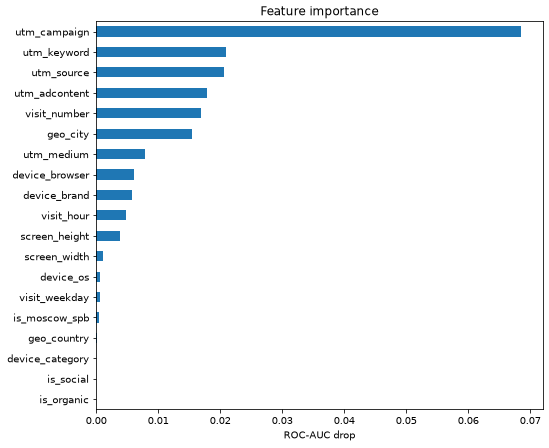

utm_campaign       0.0686
utm_keyword        0.0209
utm_source         0.0205
utm_adcontent      0.0179
visit_number       0.0169
geo_city           0.0155
utm_medium         0.0079
device_browser     0.0061
device_brand       0.0058
visit_hour         0.0048
screen_height      0.0038
screen_width       0.0011
device_os          0.0007
visit_weekday      0.0006
is_moscow_spb      0.0004
geo_country        0.0002
device_category    0.0000
is_social          0.0000
is_organic         0.0000
dtype: float64

In [13]:
sample_idx = np.random.RandomState(42).choice(len(X_valid), 200_000, replace=False)
imp = permutation_importance(model, X_valid.iloc[sample_idx], y_valid[sample_idx], scoring='roc_auc',
                             n_repeats=3, random_state=42)
importance = pd.Series(imp.importances_mean, index=X_valid.columns).sort_values()

plt.figure(figsize=(8, 7))
importance.plot(kind='barh')
plt.xlabel('ROC-AUC drop')
plt.title('Feature importance')
plt.show()
importance.sort_values(ascending=False).round(4)

utm_campaign is the most important by far (0.07), then keyword, source, ad content, visit number and city. Device and time matter little. The is_* flags are 0, the model already gets this from utm_medium, utm_source and geo_city. device_category is also 0 (brand, os and screen say the same), but it's an original field so I leave it. Trying without the flags:

In [14]:
FINAL_NUM = ['visit_number', 'visit_hour', 'visit_weekday', 'screen_width', 'screen_height']
FINAL_FEATURES = CAT_FEATURES + FINAL_NUM

model = make_model(FINAL_NUM, **best_params)
model.fit(X_train[FINAL_FEATURES], y_train)
print('without flags:', round(roc_auc_score(y_valid, model.predict_proba(X_valid[FINAL_FEATURES])[:, 1]), 4))

without flags: 0.6909


0.6909 vs 0.6917, basically the same, so I remove the flags, they only repeat other columns. Final features: 11 categorical + visit_number, hour, weekday, screen width and height.

## How much the final features depend on each other

In [15]:
print(X_train[FINAL_NUM].corr().round(2))

# strongest pairs of the categorical features (Cramer's V from above)
pairs = []
for n, a in enumerate(CAT_FEATURES):
    for b in CAT_FEATURES[n + 1:]:
        pairs.append({'feature 1': a, 'feature 2': b, 'cramers_v': cramers.loc[a, b]})
pd.DataFrame(pairs).sort_values('cramers_v', ascending=False).head(6).round(2)

               visit_number  visit_hour  visit_weekday  screen_width  \
visit_number           1.00        0.01          -0.02          0.12   
visit_hour             0.01        1.00          -0.02         -0.01   
visit_weekday         -0.02       -0.02           1.00         -0.08   
screen_width           0.12       -0.01          -0.08          1.00   
screen_height          0.06       -0.00          -0.06          0.59   

               screen_height  
visit_number            0.06  
visit_hour             -0.00  
visit_weekday          -0.06  
screen_width            0.59  
screen_height           1.00  


,feature 1,feature 2,cramers_v
54,geo_country,geo_city,0.84
10,utm_medium,utm_campaign,0.77
41,device_category,device_brand,0.71
0,utm_source,utm_medium,0.70
40,device_category,device_os,0.70
45,device_os,device_brand,0.50


The final numeric features are almost independent, the only noticeable pair is screen width and height (0.59). Among the categorical ones there are strong pairs: country and city (0.84), utm_medium and utm_campaign (0.77), utm_source and utm_medium (0.70), device_category with brand and os (about 0.7). I keep them, for boosting this is not a problem and the service has to take all utm_*, device_*, geo_* anyway. geo_country and device_category add almost nothing (importance about 0), the city and the brand already say the same.

## Results on the test set

In [16]:
results['boosting'] = {'valid': roc_auc_score(y_valid, model.predict_proba(X_valid[FINAL_FEATURES])[:, 1]),
                       'test': roc_auc_score(y_test, model.predict_proba(X_test[FINAL_FEATURES])[:, 1])}
pd.DataFrame(results).T.round(4)

,valid,test
baseline,0.6188,0.6191
logreg,0.6796,0.6757
boosting,0.6909,0.6888


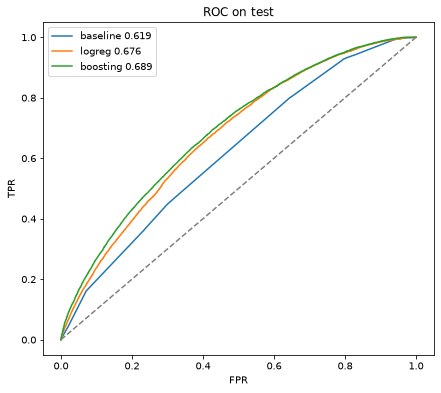

In [17]:
plt.figure(figsize=(7, 6))
for name, proba in [('baseline', baseline_proba(X_test)),
                    ('logreg', logreg.predict_proba(X_test)[:, 1]),
                    ('boosting', model.predict_proba(X_test[FINAL_FEATURES])[:, 1])]:
    fpr, tpr, _ = roc_curve(y_test, proba)
    plt.plot(fpr, tpr, label=f'{name} {roc_auc_score(y_test, proba):.3f}')
plt.plot([0, 1], [0, 1], color='grey', linestyle='--')
plt.xlabel('FPR')
plt.ylabel('TPR')
plt.title('ROC on test')
plt.legend()
plt.show()

On test: boosting 0.689, logreg 0.676, baseline 0.619. Above the 0.65 from the guide, and valid and test are close.

## Threshold and confusion matrix

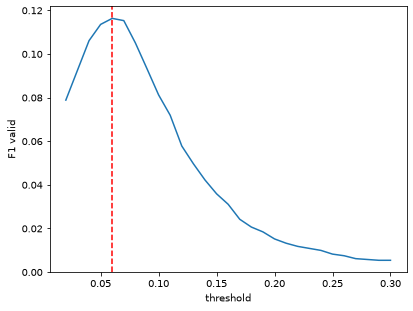

threshold: 0.06


In [18]:
# the service has to answer 0/1, with 3% positives 0.5 doesn't work, so the threshold with the best F1 on valid
valid_proba = model.predict_proba(X_valid[FINAL_FEATURES])[:, 1]
thresholds = np.arange(0.02, 0.31, 0.01).round(2)
f1s = [f1_score(y_valid, (valid_proba >= t).astype(int)) for t in thresholds]
threshold = thresholds[np.argmax(f1s)]

plt.plot(thresholds, f1s)
plt.axvline(threshold, color='red', linestyle='--')
plt.xlabel('threshold')
plt.ylabel('F1 valid')
plt.show()
print('threshold:', threshold)

In [19]:
test_proba = model.predict_proba(X_test[FINAL_FEATURES])[:, 1]
test_pred = (test_proba >= threshold).astype(int)
print('precision', round(precision_score(y_test, test_pred), 3))
print('recall', round(recall_score(y_test, test_pred), 3))
print('f1', round(f1_score(y_test, test_pred), 3))
print('share of 1:', round(test_pred.mean(), 3))
pd.DataFrame(confusion_matrix(y_test, test_pred), index=['real 0', 'real 1'], columns=['predicted 0', 'predicted 1'])

precision 0.079
recall 0.221
f1 0.117
share of 1: 0.08


,predicted 0,predicted 1
real 0,311746,25753
real 1,7844,2220


With threshold 0.06 the model says 1 for 8% of visits. 7.9% of them convert (2.9% on average, so about 2.7 times more) and it finds 22% of all target visits.

In the confusion matrix: 2220 target visits the model found, 7844 it missed, 25753 visits got 1 by mistake and 311746 are correctly 0.

## What the model means for the people who run ads

What each final feature is, in plain words:
- utm_campaign, utm_source, utm_adcontent, utm_keyword: which ad campaign, platform, banner and keyword the visit came from. This is the strongest signal;
- utm_medium: type of traffic (organic, cpc, banner, push and so on);
- visit_number: how many times the person has already been on the site;
- geo_city, geo_country: where the visit is from;
- device_category, device_os, device_brand, device_browser, screen_width, screen_height: the device;
- visit_hour, visit_weekday: when the visit happened.

So the model can be explained as "chance of a request depending on the ad, the visitor's history, place and device".

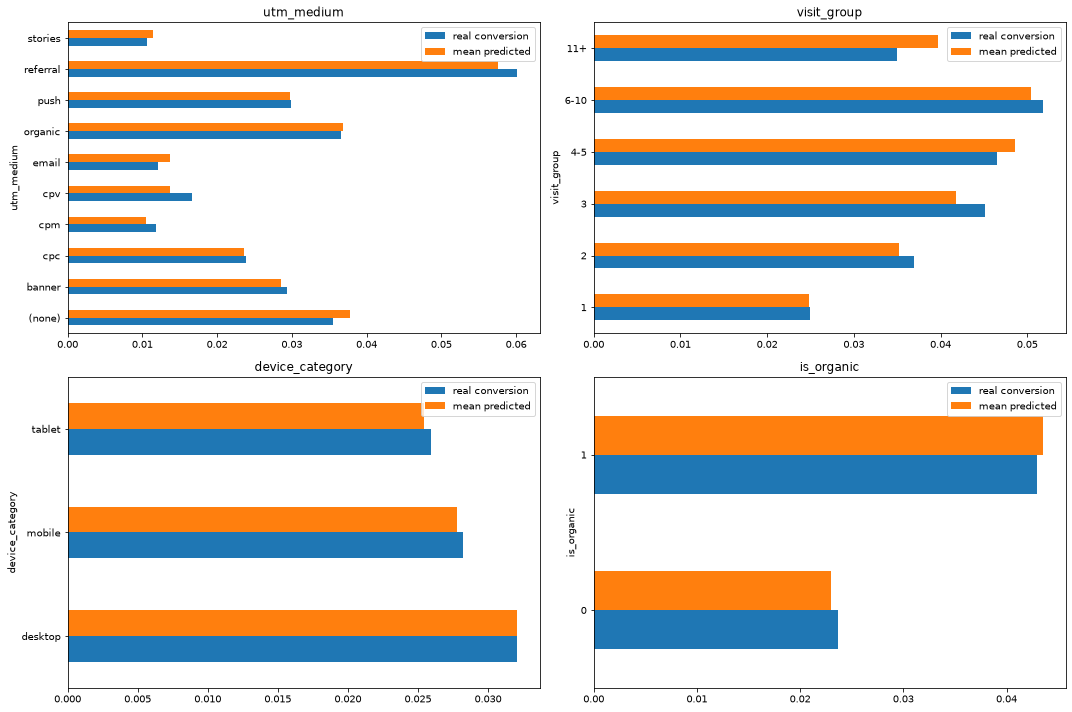

In [20]:
# predicted probability vs real conversion by groups
X_show = X_test.copy()
X_show['target'] = y_test
X_show['proba'] = test_proba
X_show['visit_group'] = pd.cut(X_show['visit_number'], [0, 1, 2, 3, 5, 10, 10000],
                               labels=['1', '2', '3', '4-5', '6-10', '11+'])

fig, axes = plt.subplots(2, 2, figsize=(15, 10))
for ax, col in zip(axes.flatten(), ['utm_medium', 'visit_group', 'device_category', 'is_organic']):
    top = X_show[col].value_counts().index[:10]
    part = X_show[X_show[col].isin(top)].groupby(col, observed=True)[['target', 'proba']].mean()
    part.plot(kind='barh', ax=ax)
    ax.set_title(col)
    ax.legend(['real conversion', 'mean predicted'])
plt.tight_layout()
plt.show()

The mean prediction is close to the real conversion in every group. Referral is the best (6%), cpm and stories the worst (about 1%), organic 4.3% vs 2.4% for paid. Conversion grows with the visit number: 2.5% on the first visit, about 5% from the 4th, but for 11+ the model is a bit too high (4% vs 3.5%). Desktop is a bit better than mobile.

## December check

Train on visits before December, test on December, to see how the model works on new data.

In [21]:
dates = pd.to_datetime(df['visit_date'])
before = (dates < '2021-12-01').values

model_time = make_model(FINAL_NUM, **best_params)
model_time.fit(X.loc[before, FINAL_FEATURES], y[before])
print('conversion before / in December:', round(y[before].mean(), 4), round(y[~before].mean(), 4))
auc_december = roc_auc_score(y[~before], model_time.predict_proba(X.loc[~before, FINAL_FEATURES])[:, 1])
print('model on December:', round(auc_december, 4))

source_cr_time = pd.Series(y[before]).groupby(X.loc[before, 'utm_source'].values).mean()
baseline_dec = X.loc[~before, 'utm_source'].map(source_cr_time).fillna(y[before].mean())
print('baseline on December:', round(roc_auc_score(y[~before], baseline_dec), 4))

pd.DataFrame({'before': X.loc[before, 'utm_source'].value_counts(normalize=True),
              'december': X.loc[~before, 'utm_source'].value_counts(normalize=True)}).sort_values('december', ascending=False).head(5).round(3)

conversion before / in December: 0.0315 0.0199


model on December: 0.6383
baseline on December: 0.5442


,before,december
utm_source,,
ZpYIoDJMcFzVoPFsHGJL,0.256,0.554
MvfHsxITijuriZxsqZqt,0.098,0.116
kjsLglQLzykiRbcDiGcD,0.160,0.073
fDLlAcSmythWSCVMvqvL,0.186,0.064
BHcvLfOaCWvWTykYqHVe,0.071,0.037


On December it's only 0.638. In December one source took 55% of the traffic instead of 26% and conversion fell from 3.15% to 2%, the baseline almost stops working there (0.544). So the model has to be retrained on fresh data, for example every month.

## Speed

The whole chain like in the service: prepare + encoder + boosting.

In [22]:
full_pipe = Pipeline([('prepare', FunctionTransformer(prepare))] + model.steps)
raw = sessions.sample(1000, random_state=1)

start = time.time()
for i in range(100):
    full_pipe.predict_proba(raw.iloc[[i]])
one_visit_ms = (time.time() - start) / 100 * 1000
print('one visit, ms:', round(one_visit_ms, 1))

start = time.time()
full_pipe.predict_proba(raw)
print('1000 visits, ms:', round((time.time() - start) * 1000, 1))

one visit, ms: 14.7
1000 visits, ms: 18.3


## Summary of the results

In [23]:
summary = pd.DataFrame(results).T.round(3)
summary.columns = ['ROC-AUC valid', 'ROC-AUC test']
print(summary)
print()
print('threshold:', threshold)
print('precision on test:', round(precision_score(y_test, test_pred), 3))
print('recall on test:', round(recall_score(y_test, test_pred), 3))
print('f1 on test:', round(f1_score(y_test, test_pred), 3))
print('ROC-AUC on December (model trained before December):', round(auc_december, 3))
print('one visit with all the preparation, ms:', round(one_visit_ms, 1))

          ROC-AUC valid  ROC-AUC test
baseline          0.619         0.619
logreg            0.680         0.676
boosting          0.691         0.689

threshold: 0.06
precision on test: 0.079
recall on test: 0.221
f1 on test: 0.117
ROC-AUC on December (model trained before December): 0.638
one visit with all the preparation, ms: 14.7


## Conclusions

- Boosting gets ROC-AUC 0.689 on test (baseline 0.619, logreg 0.676), the 0.65 from the guide is reached.
- Most important: utm campaign, keyword, source and ad content, the visit number and the city.
- The is_* flags repeated other features, so they are not in the final model.
- Threshold 0.06, these visits convert about 2.7 times more often than average.
- One visit takes about 15 ms with all the preparation, 1000 visits about 19 ms.
- On December the quality drops to 0.638, so the model needs retraining on new data.

`pipeline.py` trains the same model on all the data, `main.py` serves it.